In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import noise


c:\Users\owahl\miniconda3\Lib\site-packages\vnoise\__init__.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


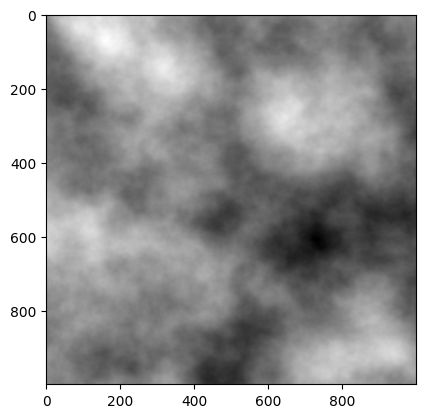

In [ ]:





# random_world = np.zeros(shape+(3,))
# for c in range(3):
#     seed =  np.random.default_rng().integers(1,1000,1)[0]
#     for i in range(shape[0]):
#         for j in range(shape[1]):
            
#                 random_world[i][j][c] = noise.pnoise2(
#                     i/scale, 
#                     j/scale, 
#                     octaves=octaves, 
#                     persistence=persistence, 
#                     lacunarity=lacunarity, 
#                     base=seed
#                 )

# random_world = (random_world - random_world.min()) / (random_world.max() - random_world.min())
# # color_world = add_color(world)
# # plt.imshow(color_world)
# # plt.show()
# plt.imshow(random_world)
# plt.show()


In [ ]:
shape = (1000,1000)
scale = 400.0
octaves = 7
persistence = 0.5
lacunarity = 2
seed =  np.random.default_rng().integers(1,scale,1)[0]

world = np.zeros(shape)
for i in range(shape[0]):
    for j in range(shape[1]):
        world[i][j] = noise.pnoise2(
            i/scale, 
            j/scale, 
            octaves=octaves, 
            persistence=persistence, 
            lacunarity=lacunarity, 
            base=seed)

# Display in black and white
plt.imshow(world, cmap="gray")
plt.show()

In [ ]:
def add_color(world):
    rules = [
        (-0.3, [0, 71, 100]),    # blue
        (-0.2, [65, 105, 255]),    # blue
        (-0.1, [85, 205, 255]),    # blue
        (-0.05, [105, 204, 225]),    # blue
        (0,     [238, 214, 175]),   # beach
        (0.1,   [34, 139, 34]),     # green
        (0.15,   [25, 119, 30]),     # green dark
        (0.25,  [112, 124, 115]),   # mountain
        (0.3,   [72, 64, 65]),   # mountain
        (0.35,  [42, 54, 55]),   # mountain midle
        (0.38,   [211, 224, 215]),   # mountain top
        (1.0,   [241, 234, 235]),   # mountain toptop
    ]

    # Normalize all colors to values between 0 and 1
    rules = [(limit, np.array(color) / 255) for limit, color in rules]

    color_world = np.zeros(world.shape + (3,))

    for i in range(world.shape[0]):
        for j in range(world.shape[1]):
            value = world[i, j]

            for limit, color in rules:
                if value < limit:
                    color_world[i, j] = color
                    break

    return color_world

In [101]:
color_world = add_color(world)
plt.imshow(color_world)

TypeError: add_color() missing 1 required positional argument: 'rules'

In [97]:
def add_color(world, rules):
    color_world = np.zeros(world.shape[:2] + (3,))

    for i in range(world.shape[0]):
        for j in range(world.shape[1]):

            for rule in rules:
                matches = True

                for dimension, limits in rule["conditions"].items():
                    minimum, maximum = limits
                    value = world[i, j, dimension]

                    if not minimum <= value < maximum:
                        matches = False
                        break

                if matches:
                    color_world[i, j] = np.array(rule["color"]) / 255
                    break

    return color_world

In [167]:
rules = [
    {
        "name": "deep_ocean",
        "conditions": {0: (-1, -0.3)},
        "color": [0, 71, 100]
    },
    {
        "name": "ocean",
        "conditions": {0: (-0.3, -0.2)},
        "color": [65, 105, 255]
    },
    {
        "name": "shallow_ocean",
        "conditions": {0: (-0.2, -0.1)},
        "color": [85, 205, 255]
    },
    {
        "name": "coastal_ocean",
        "conditions": {0: (-0.1, -0.05)},
        "color": [105, 204, 225]
    },
    {
        "name": "beach",
        "conditions": {0: (-0.05, 0.02)},
        "color": [238, 214, 175]
    },

    # DESERTS
    {
        "name": "sand_desert",
        "conditions": {0: (0.02, 0.10), 1: (-1, -0.1)},
        "color": [232, 187, 114]
    },    
    {
        "name": "sand_desert",
        "conditions": {0: (0.1, 0.25), 1: (-1, -0.1)},
        "color": [232, 214, 114]
    },
    {
        "name": "rocky_desert",
        "conditions": {0: (0.25, 0.35), 1: (-1, -0.1)},
        "color": [180, 130, 85]
    },
    {
        "name": "high_desert",
        "conditions": {0: (0.35, 1), 1: (-1, -0.1)},
        "color": [150, 120, 100]
    },

    # LAND
    {
        "name": "grassland",
        "conditions": {0: (0.02, 0.1), 1: (-0.1, 0.2)},
        "color": [34, 139, 34]
    },
       {
        "name": "wet_grassland",
        "conditions": {0: (0.02, 0.1), 1: (0.2, 1)},
        "color": [65, 145, 71]
    },
    {
        "name": "dry_grassland",
        "conditions": {0: (0.1, 0.15), 1: (-0.1, 1)},
        "color": [180, 170, 100]
    },
    {
        "name": "wet_grassland",
        "conditions": {0: (0.15, 0.2), 1: (-0.1, 1)},
        "color": [34, 139, 34]
    },
    {
        "name": "mountain",
        "conditions": {0: (0.2, 0.3), 1: (-0.1, 1)},
        "color": [58, 97, 19]
    },
    {
        "name": "mountain_dark",
        "conditions": {0: (0.3, 0.35), 1: (-0.1, 1)},
        "color": [91, 97, 91]
    },
    {
        "name": "mountain_middle",
        "conditions": {0: (0.35, 0.38), 1: (-0.1, 1)},
        "color": [153, 163, 153]
    },
    {
        "name": "mountain_top",
        "conditions": {0: (0.38, 0.5), 1: (-0.1, 1)},
        "color": [211, 224, 215]
    },
    {
        "name": "snow_peak",
        "conditions": {0: (0.5, 1), 1: (-0.1, 1)},
        "color": [241, 234, 235]
    }
]

In [162]:
dimension_settings = {
    "elevation": {
        "scale": 400.0,
        "octaves": 7,
        "persistence": 0.5,
        "lacunarity": 2,
        "seed_offset": 1
    },

    "rain": {
        "scale": 400.0,
        "octaves": 5,
        "persistence": 0.5,
        "lacunarity": 2,
        "seed_offset": 2
    },

    # "temperature": {
    #     "scale": 600.0,
    #     "octaves": 3,
    #     "persistence": 0.4,
    #     "lacunarity": 2,
    #     "seed_offset": 3
    # }
}

In [168]:

shape = (1000, 1000)
seed = np.random.default_rng().integers(1, 400)
world = np.zeros(shape + (len(dimension_settings),))
c=0
for dim, items in dimension_settings.items():
    
    settings = items
    for i in range(shape[0]):
        for j in range(shape[1]):

            world[i, j, c] = noise.pnoise2(
                i / settings["scale"],
                j / settings["scale"],
                octaves=settings["octaves"],
                persistence=settings["persistence"],
                lacunarity=settings["lacunarity"],
                base=int(seed + settings["seed_offset"])
            )
    c+=1

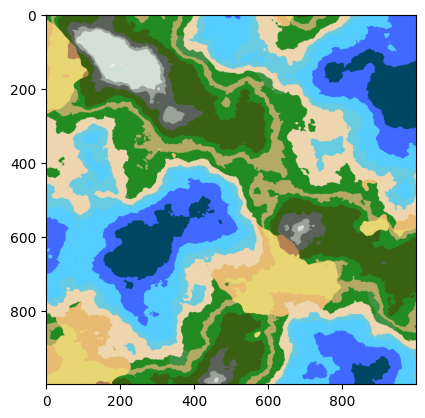

In [169]:
color_world = add_color(world, rules)
plt.imshow(color_world)

22035


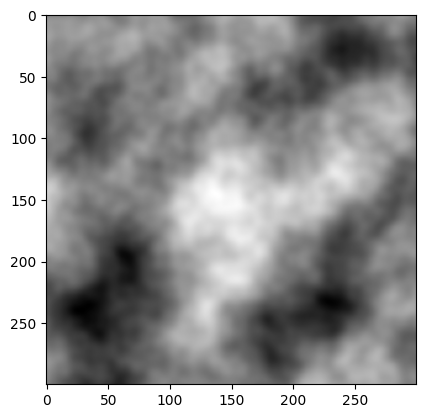

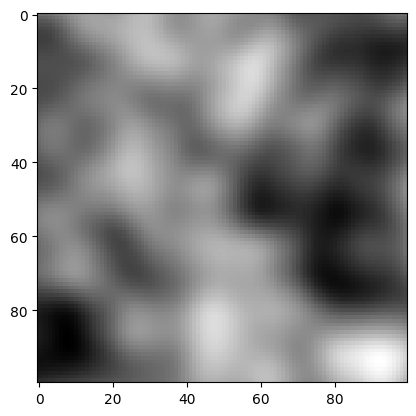

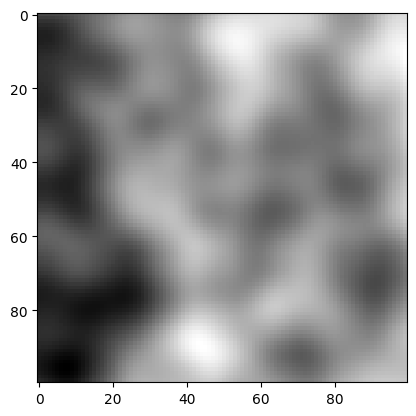

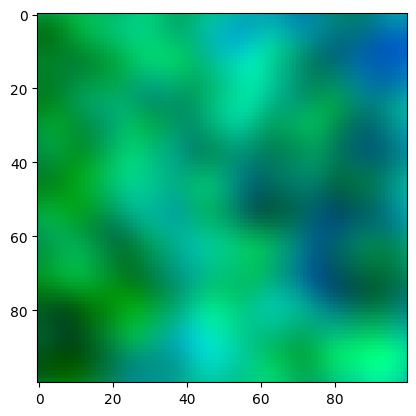

In [ ]:
seed =  np.random.default_rng().integers(1,100000,1)[0]
rng = np.random.default_rng(seed)    
print(seed)
noise=vnoise.Noise()
noise.seed(int(seed))
scale= 0.015
width, height,color = 100, 100, 2

noise_map = np.array([
    [
        [
            noise.noise3(x*scale, y*scale,t*0.3,3,0.6)
            for x in range(width)
        ]
        for y in range(height)
    ]
    for t in range(color)
])

combined = (
    noise_map[0] 
    + noise_map[1] 
    # + noise_map[2]
)

# Display in black and white
plt.imshow(world, cmap="gray")
plt.show()

plt.imshow(noise_map[0],cmap='grey')
plt.show()
plt.imshow(noise_map[1],cmap='grey')
plt.show()
# plt.imshow(noise_map[2],cmap='grey')
# plt.show()

noise_map = np.moveaxis(noise_map, 0, -1)
noise_map = (noise_map - noise_map.min()) / (noise_map.max() - noise_map.min())
rgb = np.zeros((height, width, 3))
rgb[:,:,1]=noise_map[:,:,0]
rgb[:,:,2]=noise_map[:,:,1]
plt.imshow(rgb)
plt.show()

